# Test through Inference

Test your generated safetensors model with inference on random entries from a given dataset.

Assuming that this notebook will be used after having completed a training run using the framework, it will fetch the safetensors aggregated model from the server-side Minio datastore. For this to work, place a file named `scenario.json` in the same directory as this notebook containing the scenario that has been used to train the model with.

Set the values inherent to your setup in the `Constants` section.

### Imports

In [89]:
import json
import pandas as pd
import requests
import numpy as np
import tempfile
from safetensors.tensorflow import load_file
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import random
import os
import zipfile
import shutil
from minio import Minio

### Constants

If the INFERENCE_DATASET(.parquet) is not found in this folder, the notebook will try to download it from Kaggle according to this format: [username]-[dataset]

In [ ]:
KAGGLE_BASE_URL = "https://www.kaggle.com/api/v1/datasets/download/"

INFERENCE_DATASET = "dhoogla-nfunswnb15v2" # as example

MINIO_SERVER_ENDPOINT = "[server-ip]:9000" # change with your server's IP
MINIO_SERVER_ACCESS_KEY = "aide-fl1"
MINIO_SERVER_SECRET_KEY = "aide-fl1"
MINIO_SERVER_MODELS_BUCKET = "models"

### Load scenario

In [91]:
with open("scenario.json", "r") as f:
    scenario = json.load(f)

scenario_name = scenario["name"]
label_column = scenario["label_column"]
drop_columns = scenario["preprocessing"].get("drop_columns", [])
model_json_str = json.dumps(scenario["model"])

### Download dataset

Downloads dataset from Kaggle if it doesn't already exist in this folder.

In [92]:
dataset_path = INFERENCE_DATASET + ".parquet"

if not os.path.exists(dataset_path):

    user_dataset_split = INFERENCE_DATASET.split("-")
    url = KAGGLE_BASE_URL + user_dataset_split[0] + "/" + user_dataset_split[1]
    zip_path = tempfile.mktemp(suffix=".zip")
    extract_dir = tempfile.mkdtemp()

    with requests.get(url, stream=True) as r:
        r.raise_for_status()
        with open(zip_path, 'wb') as f:
            for chunk in r.iter_content(chunk_size=8192):
                f.write(chunk)
    
    parquet_path = None
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
        for name in zip_ref.namelist():
            if name.endswith(".parquet"):
                parquet_path = os.path.join(extract_dir, name)
    
    if parquet_path is None:
        raise Exception("No Parquet file found in ZIP archive")
    
    os.remove(zip_path)

    shutil.move(parquet_path, dataset_path)

    shutil.rmtree(extract_dir)

df = pd.read_parquet(dataset_path)
print("Dataset loaded:", df.shape)

Dataset loaded: (8948, 15)


### Preprocess

Assuming that the inference dataset has te same shape and features as the training datasets, the same columns will be dropped as specified in the scenario.

In [93]:
if drop_columns:
    df = df.drop(columns=drop_columns)
print("After dropping columns:", df.shape)

After dropping columns: (8948, 14)


### Separate features and labels

In [94]:
X = df.drop(columns=[label_column])
y = df[label_column]

### Encode labels

In [95]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

### Download model

In [96]:
model_path = scenario_name + ".safetensors"

minio_client = Minio(MINIO_SERVER_ENDPOINT, access_key=MINIO_SERVER_ACCESS_KEY, secret_key=MINIO_SERVER_SECRET_KEY, secure=False)

minio_client.fget_object(MINIO_SERVER_MODELS_BUCKET, model_path, model_path)

### Load safetensors weights into Keras model

In [97]:
model = tf.keras.models.model_from_json(model_json_str)

weights_dict = load_file(model_path)

# Sort keys numerically to ensure correct order
ordered_keys = sorted(weights_dict.keys(), key=lambda k: int(k.split("_")[1]))
weights_list = [weights_dict[k].numpy() for k in ordered_keys]

# Set all weights at once
model.set_weights(weights_list)

### Inference

In [98]:
sample_indices = random.sample(range(len(X)), 1000)
X_sample = X.iloc[sample_indices].values
y_sample = y_encoded[sample_indices]

def predict_classes(y_pred_probs, threshold=0.5):
    if y_pred_probs.ndim == 1 or (y_pred_probs.ndim == 2 and y_pred_probs.shape[1] == 1):
        # Binary classification (sigmoid output)
        return (y_pred_probs.ravel() > threshold).astype(int)
    else:
        # Multiclass classification (softmax output)
        return np.argmax(y_pred_probs, axis=1)

y_pred_probs = model.predict(X_sample)
y_pred = predict_classes(y_pred_probs)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


### Confusion matrix

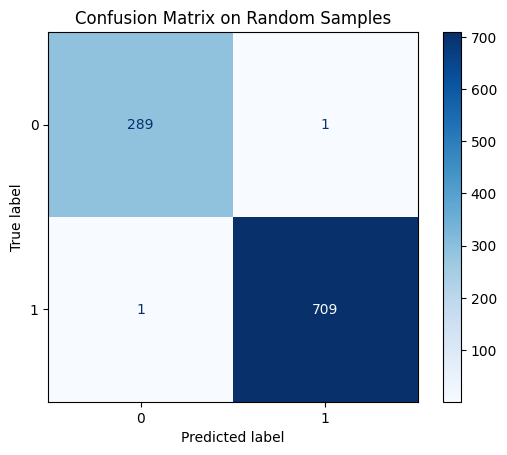

In [99]:
cm = confusion_matrix(y_sample, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix on Random Samples")
plt.show()